<a href="https://colab.research.google.com/github/metrosmash/myflyrank-ml-internship/blob/main/work/notebooks/w01_research_question.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML-02 — Research Question and Provisional Lane

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/metrosmash/myflyrank-ml-internship/blob/main/work/notebooks/w01_research_question.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. My lane (or freestyle) and why

*Name your lane — or say 'freestyle' and describe your own question. One short paragraph: why this one?*

### Lane 4: CTR / Engagement Opportunity Scoring

In this Lane i would specifically be asking the question of why a page is visible but doesnt have enough clicks or engagement
then  i would cluster the pages into groups based of this search
For Example:
1. healthy - visible page also nice ctr (can also be more narrow)
2. too broad/general - visible page but spread thin around different subjects
3. etc

In [39]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/flyrank-bih/flyrank-ml-internship-starter"
REPO_DIR = "flyrank-ml-internship-starter"

if IN_COLAB:
    if not os.path.isdir(REPO_DIR):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:
    # find the repo root from wherever this kernel started
    while not os.path.isdir("data/raw") and os.getcwd() != "/":
        os.chdir("..")

print("Working dir:", os.getcwd())
assert os.path.exists("data/raw/content_refresh_anonymized.csv"), "starter CSV not found — are you at the repo root?"
print("Starter data found. You're ready.")

Working dir: /content/flyrank-ml-internship-starter/flyrank-ml-internship-starter/flyrank-ml-internship-starter
Starter data found. You're ready.


## 2. The question: decision, action, cost of a wrong call

*What decision does your work improve? Who acts on it? What does a wrong recommendation cost?*

- what decision does your work improve?

its used to point out the problem the page might have and possibly how to fix it. and also group the pages together so you can check if your page is just very visible but isnt attracting the right attention.

- who acts on it?

Seo optimization companies,seo analysts

- what does wrong recommendation cost?

`The cost of misclassification is asymmetric and directional`
what this means from my POV is that we can take away what was good about the page if the page is supposed to be that way

- what does it cost to miss a real problem (false negative)

we provide inconclusive solutions or clusters that misleads the customer

In [40]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 3. Quick look at the data (2-3 real numbers)

*Load the starter CSV below and show 2-3 real numbers that make your lane look worth the next 7 weeks.*

In [41]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

df = pd.read_csv("data/raw/content_refresh_anonymized.csv")

df.head()

,content_id,client_id,search_volume,competition,competition_level,cpc,content_type,main_intent,word_count,char_count,...,char_count_tier,ctr,avg_position,engagement_rate,scroll_rate,ai_traffic_pct,impression_tier,position_tier,trend_direction,trend_pct
0,content_304f48230142,client_f369cb89fc,10.0,0.67,HIGH,2.05,keyword article,transactional,3221.0,20457.0,...,15000-25000,0.76,10.6,5.88,4.55,0.0,good,striking,down,-41.4
1,content_a1fb4e703a9e,client_4e07408562,90.0,0.01,LOW,0.05,keyword article,informational,2481.0,15562.0,...,15000-25000,0.05,20.3,0.00,10.00,0.0,good,page_3_5,down,-57.7
2,content_9aa793d4d895,client_7f2253d7e2,0.0,0.00,LOW,0.00,keyword article,informational,3515.0,23643.0,...,15000-25000,0.09,36.5,0.00,28.57,0.0,good,page_3_5,down,-60.9
3,content_331d6c4de07b,client_19581e27de,10.0,0.00,LOW,0.00,keyword article,commercial,NaN,NaN,...,NaN,0.49,6.2,1.28,3.45,0.0,good,page_1,stable,-13.8
4,content_d99b7a2d90ca,client_3fdba35f04,0.0,0.00,LOW,0.00,keyword article,informational,2803.0,17469.0,...,15000-25000,0.13,44.0,0.00,24.29,0.0,good,page_3_5,down,-34.7


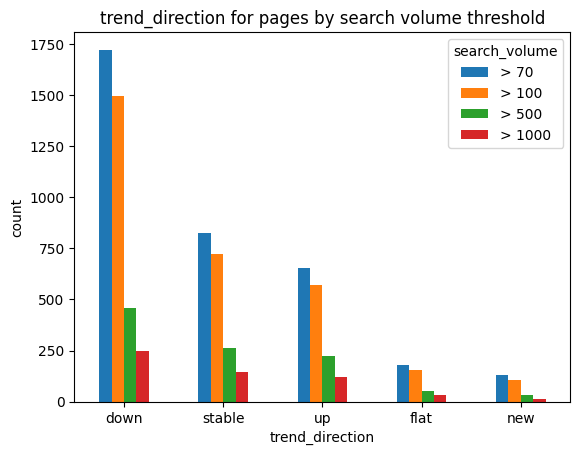

In [42]:
# ploting the trend direction for each high search volume page
thresholds = [70, 100, 500, 1000]

# Count trend_direction for each threshold
counts = {}
for t in thresholds:
    subset = df[df["search_volume"] > t]
    counts[f"> {t}"] = subset["trend_direction"].value_counts()

# Combine into one table: rows = trend_direction, columns = threshold
hsv_trend_table = pd.DataFrame(counts).fillna(0).astype(int)

# Grouped bar chart
ax = hsv_trend_table.plot(
    kind="bar",
    title="trend_direction for pages by search volume threshold",
    ylabel="count",
    xlabel="trend_direction",
    rot=0,
)
ax.legend(title="search_volume")

i think this shows that its worth checking
this pages have search volume in the hundreds but not enough trend

## 4. Careful words: what I can and can't claim

*Write what your work will be able to say (observed, directional, decision-support) — and what it never will (causal proof, 'predicting Google').*

### What this work can claim:

  - Observed Signals & Patterns: Empirical identification of high-impression pages that under-capture clicks (low CTR) or onsite user interaction (low engagement).

  - Directional Prioritization: Data-backed recommendations on whether a flagged page primarily needs a Metadata overhaul (SERP level), a Content rewrite (on-page level), or extended Monitoring review.

  - Decision Support: Actionable prioritization frameworks to maximize organic traffic ROI from existing site assets.

### What this work will never claim:

  - Causal Proof or Reverse-Engineering: Reverse-engineering Google’s exact ranking weights, machine learning sub-models, or algorithmic decision trees.

  - Deterministic Predictions: Guaranteeing exact position bumps or predicting the precise mechanical reason why Google’s index assigned high visibility to a specific page.

In [43]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## Self-check

Before you submit, confirm each line honestly:

- [*] Every section above is filled — markdown thinking AND the code that backs it
- [*] The notebook runs top to bottom with no errors (Runtime → Run all)
- [*] No client names, URLs, or private queries anywhere
- [*] My claims use careful words: observed, measured, directional, decision-support
- [*] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.

In [44]:
print("Run ALL- Succeeded")

Run ALL- Succeeded
